In [1]:
!pip -q install diffusers

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchvision.datasets import MNIST
from torch.utils.data import DataLoader, TensorDataset
from diffusers import UNet2DModel, DDPMScheduler

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

dataset = MNIST("./data", train=True, download=True)

images = dataset.data[:10000].unsqueeze(1).float() / 127.5 - 1

labels = dataset.targets[:len(images)]

cfg_dataset = TensorDataset(images, labels)

cfg_loader = DataLoader(
    cfg_dataset,
    batch_size=64,
    shuffle=True
)

Using: cuda


In [2]:
cfg_model = UNet2DModel(
    sample_size=28,
    in_channels=1,
    out_channels=1,
    layers_per_block=2,
    block_out_channels=(32, 64),
    down_block_types=("DownBlock2D", "AttnDownBlock2D"),
    up_block_types=("AttnUpBlock2D", "UpBlock2D"),
    norm_num_groups=8,
    num_class_embeds=11
).to(device)

cfg_scheduler = DDPMScheduler(num_train_timesteps=1000)
cfg_optimizer = torch.optim.Adam(cfg_model.parameters(), lr=1e-3)

In [3]:
for epoch in range(10):
    cfg_model.train()

    for clean_images, labels in cfg_loader:
        clean_images = clean_images.to(device)
        labels = labels.to(device)

        noise = torch.randn_like(clean_images)

        timesteps = torch.randint(0, 1000, (clean_images.shape[0],), device=device)

        noisy_images = cfg_scheduler.add_noise(clean_images, noise, timesteps)

        drop_mask = torch.rand(labels.shape, device=device) < 0.1
        labels_for_model = labels.clone()
        labels_for_model[drop_mask] = 10

        predicted_noise = cfg_model(
            noisy_images,
            timesteps,
            class_labels=labels_for_model
        ).sample

        loss = F.mse_loss(predicted_noise, noise)

        cfg_optimizer.zero_grad()
        loss.backward()
        cfg_optimizer.step()

    print("Epoch:", epoch + 1, "Last batch loss:", loss.item())

Epoch: 1 Last batch loss: 0.048755984753370285
Epoch: 2 Last batch loss: 0.023315580561757088
Epoch: 3 Last batch loss: 0.016769034788012505
Epoch: 4 Last batch loss: 0.04824516549706459
Epoch: 5 Last batch loss: 0.031961772590875626
Epoch: 6 Last batch loss: 0.016998879611492157
Epoch: 7 Last batch loss: 0.022801868617534637
Epoch: 8 Last batch loss: 0.038463253527879715
Epoch: 9 Last batch loss: 0.012953931465744972
Epoch: 10 Last batch loss: 0.03927396237850189


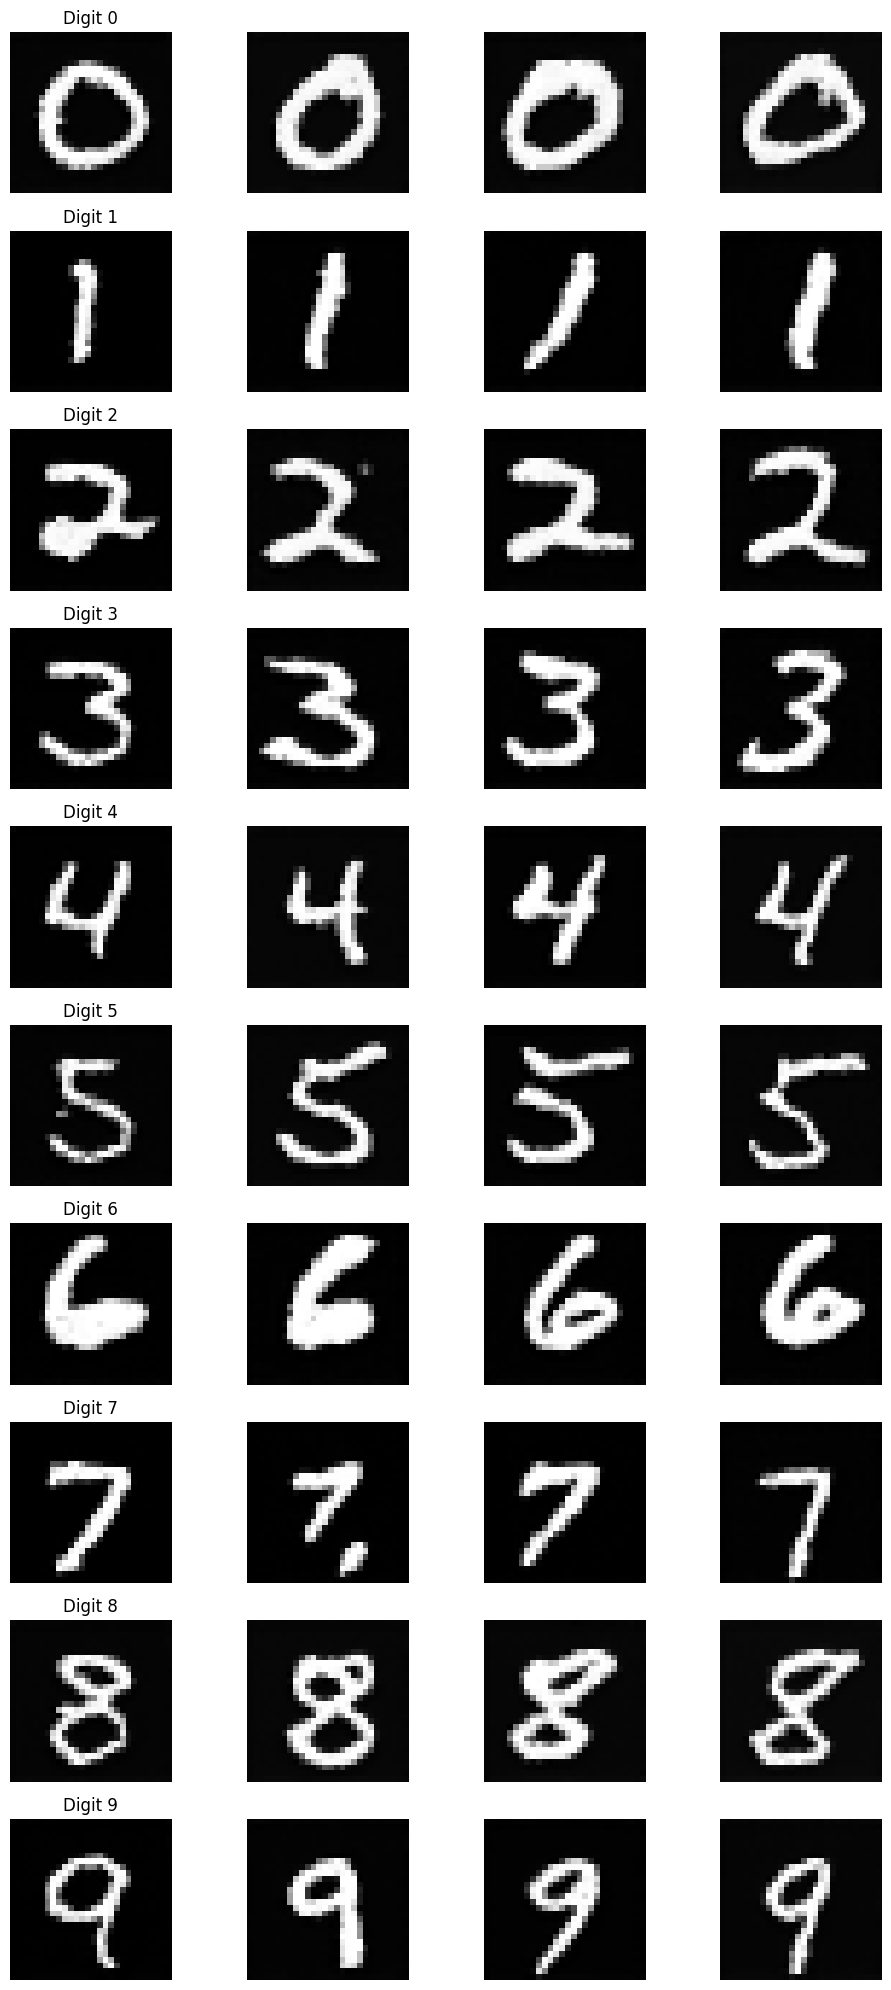

In [4]:
guidance_scale = 3

digits = list(range(10))

cfg_model.eval()
cfg_scheduler.set_timesteps(100)

fig, axes = plt.subplots(10, 4, figsize=(10, 20))

for row, digit in enumerate(digits):
    torch.manual_seed(42)
    sample = torch.randn(4, 1, 28, 28, device=device)
    cond_labels = torch.full((4,), digit, dtype=torch.long, device=device)
    uncond_labels = torch.full((4,), 10, dtype=torch.long, device=device)

    with torch.no_grad():
        for t in cfg_scheduler.timesteps:
            noise_cond = cfg_model(sample, t, class_labels=cond_labels).sample
            noise_uncond = cfg_model(sample, t, class_labels=uncond_labels).sample
            guided_noise = noise_uncond + guidance_scale * (noise_cond - noise_uncond)
            sample = cfg_scheduler.step(guided_noise, t, sample).prev_sample

    for col in range(4):
        image = ((sample[col, 0] + 1) / 2).clamp(0, 1).cpu()
        axes[row, col].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")

    axes[row, 0].set_title(f"Digit {digit}")

plt.tight_layout()
plt.show()